<a href="https://colab.research.google.com/github/souha24-ctrl/discursive-stance-analyzer/blob/main/stance_analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lightweight Discursive Stance Analyzer

This notebook segments long-form argumentative text into sentence-level propositions and classifies each proposition as **supporting**, **opposing**, or **neutral** toward a target premise.

## Research question

Can a lightweight zero-shot NLP pipeline identify the argumentative stance of individual statements toward a policy claim?

## Pipeline

1. Clean raw text.
2. Segment text into sentences using spaCy.
3. Classify each sentence against a target premise using `facebook/bart-large-mnli`.
4. Evaluate predictions on a labeled dataset.
5. Discuss limitations and possible improvements.

In [1]:
# Install core libraries for segmentation, classification, evaluation, and visualization
!pip install -q spacy transformers torch pandas scikit-learn matplotlib seaborn

# Download spaCy's small English model
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import spacy
import torch
import transformers
import pandas as pd
import sklearn

print("spaCy:", spacy.__version__)
print("Transformers:", transformers.__version__)
print("Torch:", torch.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())

spaCy: 3.8.16
Transformers: 5.20.2
Torch: 2.11.0+cu130
Pandas: 2.2.3
scikit-learn: 1.6.1
GPU available: True


In [3]:
import re
import spacy

# Load the small English spaCy pipeline
nlp = spacy.load("en_core_web_sm")


def clean_text(text: str) -> str:
    """Normalize whitespace and remove URLs and excessive special characters."""
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^\w\s.,;:!?()\"'-]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def segment_text(text: str) -> list[str]:
    """Clean a long text and return sentence-level propositions."""
    cleaned_text = clean_text(text)
    doc = nlp(cleaned_text)
    return [sent.text.strip() for sent in doc.sents if sent.text.strip()]


sample_text = """
Universal basic income could reduce poverty by giving people a guaranteed income floor.
However, critics argue that it may be too expensive for governments to sustain.
Some studies suggest that direct cash transfers can improve financial stability.
Others believe that such programs could reduce incentives to work.
"""

sentences = segment_text(sample_text)

for i, sentence in enumerate(sentences, start=1):
    print(f"{i}. {sentence}")

1. Universal basic income could reduce poverty by giving people a guaranteed income floor.
2. However, critics argue that it may be too expensive for governments to sustain.
3. Some studies suggest that direct cash transfers can improve financial stability.
4. Others believe that such programs could reduce incentives to work.


In [4]:
import torch
from transformers import pipeline

# Load once; do not reload this for every sentence

# Automatically use GPU if available, otherwise use CPU
device = 0 if torch.cuda.is_available() else -1

print("Using device:", "GPU" if device == 0 else "CPU")

stance_classifier = pipeline(
    task="zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=device
)

CANDIDATE_LABELS = ["support", "oppose", "neutral"]

Using device: GPU


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [5]:
def classify_stance(
    sentences: list[str],
    target_premise: str,
    batch_size: int = 4
) -> list[dict]:
    """
    Classify each sentence's stance toward a target premise.

    Returns a list of dictionaries:
    {
        "sentence": ...,
        "stance": ...,
        "confidence": ...
    }
    """
    results = []

    for start in range(0, len(sentences), batch_size):
        batch = sentences[start:start + batch_size]

        outputs = stance_classifier(
            batch,
            candidate_labels=CANDIDATE_LABELS,
            multi_label=False
        )

        # When one text is provided, Transformers may return a dict instead of a list
        if isinstance(outputs, dict):
            outputs = [outputs]

        for sentence, output in zip(batch, outputs):
            results.append({
                "sentence": sentence,
                "stance": output["labels"][0],
                "confidence": round(float(output["scores"][0]), 4)
            })

    return results


target_premise = "Universal basic income is beneficial"

stance_results = classify_stance(sentences, target_premise)

for result in stance_results:
    print(f"[{result['stance'].upper()}] {result['confidence']:.2f} — {result['sentence']}")

[SUPPORT] 0.93 — Universal basic income could reduce poverty by giving people a guaranteed income floor.
[OPPOSE] 0.83 — However, critics argue that it may be too expensive for governments to sustain.
[SUPPORT] 0.85 — Some studies suggest that direct cash transfers can improve financial stability.
[OPPOSE] 0.91 — Others believe that such programs could reduce incentives to work.


In [6]:
results_df = pd.DataFrame(stance_results)
results_df

,sentence,stance,confidence
0,Universal basic income could reduce poverty by...,support,0.9260
1,"However, critics argue that it may be too expe...",oppose,0.8301
2,Some studies suggest that direct cash transfer...,support,0.8540
3,Others believe that such programs could reduce...,oppose,0.9105


## Evaluation on a small labeled set

To evaluate the zero-shot classifier, we construct a small manually labeled evaluation set.
Each sentence is labeled according to its stance toward the target premise:

- `support`: the sentence gives a reason or evidence in favor of the premise.
- `oppose`: the sentence gives a reason or evidence against the premise.
- `neutral`: the sentence is factual, contextual, or does not clearly favor either side.

This evaluation set is intentionally small and is used to demonstrate the evaluation workflow.## Evaluation on a small labeled set

To evaluate the zero-shot classifier, we construct a small manually labeled evaluation set.
Each sentence is labeled according to its stance toward the target premise:

- `support`: the sentence gives a reason or evidence in favor of the premise.
- `oppose`: the sentence gives a reason or evidence against the premise.
- `neutral`: the sentence is factual, contextual, or does not clearly favor either side.

This evaluation set is intentionally small and is used to demonstrate the evaluation workflow.

In [7]:
import pandas as pd

target_premise = "Universal basic income is beneficial"

evaluation_data = [
    {
        "sentence": "Universal basic income could reduce poverty by providing a guaranteed income floor.",
        "true_stance": "support"
    },
    {
        "sentence": "Direct cash transfers can improve financial stability for low-income households.",
        "true_stance": "support"
    },
    {
        "sentence": "A basic income may give people more freedom to invest in education or start businesses.",
        "true_stance": "support"
    },
    {
        "sentence": "Guaranteed income could reduce anxiety caused by unpredictable employment.",
        "true_stance": "support"
    },
    {
        "sentence": "Universal basic income may simplify welfare systems by replacing multiple benefits.",
        "true_stance": "support"
    },
    {
        "sentence": "Critics argue that universal basic income may be too expensive for governments to sustain.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Some economists believe that guaranteed income could reduce incentives to work.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Opponents warn that funding a universal payment would require higher taxes.",
        "true_stance": "oppose"
    },
    {
        "sentence": "A basic income might increase inflation if demand rises faster than production.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Critics say that universal payments could disproportionately benefit people who do not need assistance.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Universal basic income is a policy proposal that has been discussed in many countries.",
        "true_stance": "neutral"
    },
    {
        "sentence": "Several pilot programs have tested forms of guaranteed income.",
        "true_stance": "neutral"
    },
    {
        "sentence": "The effects of basic income may vary depending on the amount paid and local economic conditions.",
        "true_stance": "neutral"
    },
    {
        "sentence": "Researchers continue to study the long-term impact of cash-transfer programs.",
        "true_stance": "neutral"
    },
    {
        "sentence": "Public opinion on universal basic income differs across political groups.",
        "true_stance": "neutral"
    }
]

evaluation_df = pd.DataFrame(evaluation_data)
evaluation_df

,sentence,true_stance
0,Universal basic income could reduce poverty by...,support
1,Direct cash transfers can improve financial st...,support
2,A basic income may give people more freedom to...,support
3,Guaranteed income could reduce anxiety caused ...,support
4,Universal basic income may simplify welfare sy...,support
5,Critics argue that universal basic income may ...,oppose
6,Some economists believe that guaranteed income...,oppose
7,Opponents warn that funding a universal paymen...,oppose
8,A basic income might increase inflation if dem...,oppose
9,Critics say that universal payments could disp...,oppose


### Labeling rules

A sentence is labeled `support` if it presents a potential benefit, advantage, or positive consequence of universal basic income.

A sentence is labeled `oppose` if it presents a cost, risk, disadvantage, or argument against universal basic income.

A sentence is labeled `neutral` if it describes the topic without clearly arguing for or against it.

These labels represent the stance expressed by the sentence, not necessarily the personal opinion of the speaker.

In [8]:
from tqdm.auto import tqdm

predictions = []

for sentence in tqdm(evaluation_df["sentence"], desc="Classifying sentences"):
    result = classify_stance(
        sentences=[sentence],
        target_premise=target_premise,
        batch_size=1
    )[0]

    predictions.append(result["stance"])

evaluation_df["predicted_stance"] = predictions
evaluation_df

Classifying sentences:   0%|          | 0/15 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,sentence,true_stance,predicted_stance
0,Universal basic income could reduce poverty by...,support,support
1,Direct cash transfers can improve financial st...,support,support
2,A basic income may give people more freedom to...,support,support
3,Guaranteed income could reduce anxiety caused ...,support,support
4,Universal basic income may simplify welfare sy...,support,support
5,Critics argue that universal basic income may ...,oppose,oppose
6,Some economists believe that guaranteed income...,oppose,oppose
7,Opponents warn that funding a universal paymen...,oppose,oppose
8,A basic income might increase inflation if dem...,oppose,oppose
9,Critics say that universal payments could disp...,oppose,oppose


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

true_labels = evaluation_df["true_stance"]
predicted_labels = evaluation_df["predicted_stance"]

accuracy = accuracy_score(true_labels, predicted_labels)
precision, recall, f1, support = precision_recall_fscore_support(
    true_labels,
    predicted_labels,
    labels=CANDIDATE_LABELS,
    average="weighted",
    zero_division=0
)

print(f"Accuracy: {accuracy:.3f}")
print(f"Weighted precision: {precision:.3f}")
print(f"Weighted recall: {recall:.3f}")
print(f"Weighted F1-score: {f1:.3f}")

print("\nClassification report:")
print(classification_report(
    true_labels,
    predicted_labels,
    labels=CANDIDATE_LABELS,
    zero_division=0
))

Accuracy: 0.667
Weighted precision: 0.500
Weighted recall: 0.667
Weighted F1-score: 0.556

Classification report:
              precision    recall  f1-score   support

     support       0.50      1.00      0.67         5
      oppose       1.00      1.00      1.00         5
     neutral       0.00      0.00      0.00         5

    accuracy                           0.67        15
   macro avg       0.50      0.67      0.56        15
weighted avg       0.50      0.67      0.56        15



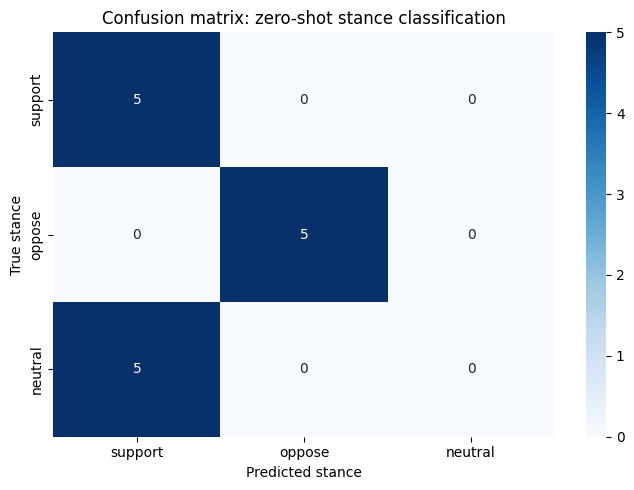

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=CANDIDATE_LABELS
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CANDIDATE_LABELS,
    yticklabels=CANDIDATE_LABELS
)

plt.xlabel("Predicted stance")
plt.ylabel("True stance")
plt.title("Confusion matrix: zero-shot stance classification")
plt.tight_layout()
plt.show()

### Initial interpretation

The classifier correctly identifies many clearly supportive and opposing statements. However, zero-shot classification may confuse neutral statements with weak support or opposition because the model must choose one of only three labels.

The small evaluation set is not statistically representative. It is used here to demonstrate a reproducible evaluation workflow and to identify common error patterns.

In [11]:
evaluation_df.to_csv("stance_evaluation_results.csv", index=False)
print("Saved:", "stance_evaluation_results.csv")
evaluation_df

Saved: stance_evaluation_results.csv


,sentence,true_stance,predicted_stance
0,Universal basic income could reduce poverty by...,support,support
1,Direct cash transfers can improve financial st...,support,support
2,A basic income may give people more freedom to...,support,support
3,Guaranteed income could reduce anxiety caused ...,support,support
4,Universal basic income may simplify welfare sy...,support,support
5,Critics argue that universal basic income may ...,oppose,oppose
6,Some economists believe that guaranteed income...,oppose,oppose
7,Opponents warn that funding a universal paymen...,oppose,oppose
8,A basic income might increase inflation if dem...,oppose,oppose
9,Critics say that universal payments could disp...,oppose,oppose


### Improving zero-shot prompts

The initial classifier used short labels: `support`, `oppose`, and `neutral`.
Because zero-shot classification converts labels into natural-language hypotheses,
vague labels can lead to systematic errors.

We now test a more explicit hypothesis template that describes the relationship
between a statement and the target premise.

In [12]:
def classify_stance_v2(
    sentences: list[str],
    target_premise: str,
    batch_size: int = 4
) -> list[dict]:
    """
    Classify stance using a more explicit zero-shot hypothesis template.
    """
    candidate_labels = [
        "supports the premise",
        "opposes the premise",
        "is neutral toward the premise"
    ]

    hypothesis_template = (
        "This statement {} the following claim: " + target_premise + "."
    )

    results = []

    for start in range(0, len(sentences), batch_size):
        batch = sentences[start:start + batch_size]

        outputs = stance_classifier(
            batch,
            candidate_labels=candidate_labels,
            hypothesis_template=hypothesis_template,
            multi_label=False
        )

        if isinstance(outputs, dict):
            outputs = [outputs]

        label_mapping = {
            "supports the premise": "support",
            "opposes the premise": "oppose",
            "is neutral toward the premise": "neutral"
        }

        for sentence, output in zip(batch, outputs):
            raw_label = output["labels"][0]

            results.append({
                "sentence": sentence,
                "stance": label_mapping[raw_label],
                "confidence": round(float(output["scores"][0]), 4)
            })

    return results

In [13]:
test_sentences = [
    "Universal basic income is a policy proposal that has been discussed in many countries.",
    "Universal basic income could reduce poverty by providing a guaranteed income floor.",
    "Critics argue that universal basic income may be too expensive for governments to sustain."
]

for sentence in test_sentences:
    result = classify_stance_v2([sentence], target_premise)[0]
    print(f"[{result['stance'].upper()}] {result['confidence']:.2f} — {sentence}")

[SUPPORT] 0.73 — Universal basic income is a policy proposal that has been discussed in many countries.
[SUPPORT] 0.87 — Universal basic income could reduce poverty by providing a guaranteed income floor.
[OPPOSE] 0.93 — Critics argue that universal basic income may be too expensive for governments to sustain.


In [14]:
v2_predictions = []

for sentence in tqdm(evaluation_df["sentence"], desc="Classifying with improved prompt"):
    result = classify_stance_v2(
        sentences=[sentence],
        target_premise=target_premise,
        batch_size=1
    )[0]

    v2_predictions.append(result["stance"])

evaluation_df["predicted_stance_v2"] = v2_predictions
evaluation_df

Classifying with improved prompt:   0%|          | 0/15 [00:00<?, ?it/s]

,sentence,true_stance,predicted_stance,predicted_stance_v2
0,Universal basic income could reduce poverty by...,support,support,support
1,Direct cash transfers can improve financial st...,support,support,support
2,A basic income may give people more freedom to...,support,support,support
3,Guaranteed income could reduce anxiety caused ...,support,support,support
4,Universal basic income may simplify welfare sy...,support,support,support
5,Critics argue that universal basic income may ...,oppose,oppose,oppose
6,Some economists believe that guaranteed income...,oppose,oppose,oppose
7,Opponents warn that funding a universal paymen...,oppose,oppose,oppose
8,A basic income might increase inflation if dem...,oppose,oppose,oppose
9,Critics say that universal payments could disp...,oppose,oppose,oppose


In [15]:
from sklearn.metrics import classification_report, accuracy_score

print("Version 1: short labels")
print(classification_report(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("\nVersion 2: explicit hypothesis template")
print(classification_report(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v2"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("Accuracy v1:", accuracy_score(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance"]
))

print("Accuracy v2:", accuracy_score(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v2"]
))

Version 1: short labels
              precision    recall  f1-score   support

     support       0.50      1.00      0.67         5
      oppose       1.00      1.00      1.00         5
     neutral       0.00      0.00      0.00         5

    accuracy                           0.67        15
   macro avg       0.50      0.67      0.56        15
weighted avg       0.50      0.67      0.56        15


Version 2: explicit hypothesis template
              precision    recall  f1-score   support

     support       0.71      1.00      0.83         5
      oppose       0.83      1.00      0.91         5
     neutral       1.00      0.40      0.57         5

    accuracy                           0.80        15
   macro avg       0.85      0.80      0.77        15
weighted avg       0.85      0.80      0.77        15

Accuracy v1: 0.6666666666666666
Accuracy v2: 0.8


### Prompt sensitivity

Zero-shot classification is sensitive to the wording of candidate labels and hypothesis templates.
The first version used simple class names, while the second version explicitly describes the
relationship between a statement and the target premise.

Comparing both versions shows that prompt design can change model behavior without retraining
the model. This is an important limitation and research consideration for zero-shot NLI systems.

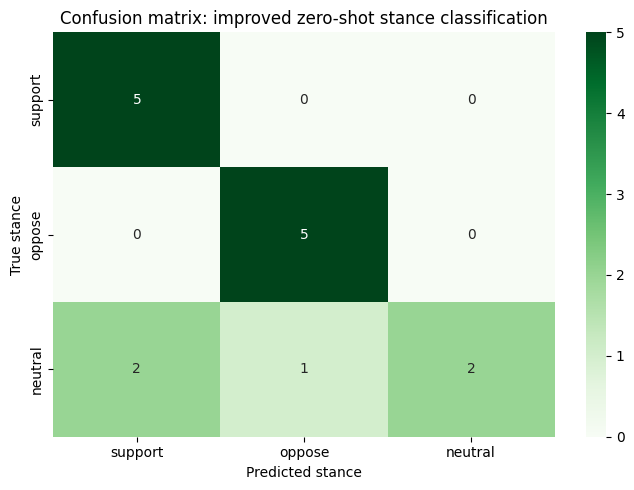

In [16]:
cm_v2 = confusion_matrix(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v2"],
    labels=CANDIDATE_LABELS
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CANDIDATE_LABELS,
    yticklabels=CANDIDATE_LABELS
)

plt.xlabel("Predicted stance")
plt.ylabel("True stance")
plt.title("Confusion matrix: improved zero-shot stance classification")
plt.tight_layout()
plt.show()

### Version 3: refining the neutral class

The improved prompt increased overall accuracy, but neutral statements remain difficult.
Some neutral statements describe the policy, existing research, or public disagreement
without explicitly supporting or opposing it.

We now test a more explicit neutral hypothesis that emphasizes the absence of a clear argument.

In [17]:
def classify_stance_v3(
    sentences: list[str],
    target_premise: str,
    batch_size: int = 4
) -> list[dict]:
    """
    Classify stance using a more explicit neutral hypothesis.
    """
    candidate_labels = [
        "provides an argument or evidence supporting the claim",
        "provides an argument or evidence against the claim",
        "does not provide a clear argument for or against the claim"
    ]

    hypothesis_template = (
        "Regarding the claim that " + target_premise + ", this statement {}."
    )

    label_mapping = {
        "provides an argument or evidence supporting the claim": "support",
        "provides an argument or evidence against the claim": "oppose",
        "does not provide a clear argument for or against the claim": "neutral"
    }

    results = []

    for start in range(0, len(sentences), batch_size):
        batch = sentences[start:start + batch_size]

        outputs = stance_classifier(
            batch,
            candidate_labels=candidate_labels,
            hypothesis_template=hypothesis_template,
            multi_label=False
        )

        if isinstance(outputs, dict):
            outputs = [outputs]

        for sentence, output in zip(batch, outputs):
            raw_label = output["labels"][0]

            results.append({
                "sentence": sentence,
                "stance": label_mapping[raw_label],
                "confidence": round(float(output["scores"][0]), 4)
            })

    return results

In [18]:
problem_sentences = [
    "Universal basic income is a policy proposal that has been discussed in many countries.",
    "Several pilot programs have tested forms of guaranteed income.",
    "The effects of basic income may vary depending on the amount paid and local economic conditions.",
    "Researchers continue to study the long-term impact of cash-transfer programs.",
    "Public opinion on universal basic income differs across political groups."
]

for sentence in problem_sentences:
    result = classify_stance_v3([sentence], target_premise)[0]
    print(f"[{result['stance'].upper()}] {result['confidence']:.2f} — {sentence}")

[SUPPORT] 0.67 — Universal basic income is a policy proposal that has been discussed in many countries.
[SUPPORT] 0.75 — Several pilot programs have tested forms of guaranteed income.
[OPPOSE] 0.35 — The effects of basic income may vary depending on the amount paid and local economic conditions.
[SUPPORT] 0.45 — Researchers continue to study the long-term impact of cash-transfer programs.
[SUPPORT] 0.41 — Public opinion on universal basic income differs across political groups.


In [19]:
v3_predictions = []

for sentence in tqdm(evaluation_df["sentence"], desc="Classifying with Version 3"):
    result = classify_stance_v3(
        sentences=[sentence],
        target_premise=target_premise,
        batch_size=1
    )[0]

    v3_predictions.append(result["stance"])

evaluation_df["predicted_stance_v3"] = v3_predictions
evaluation_df

Classifying with Version 3:   0%|          | 0/15 [00:00<?, ?it/s]

,sentence,true_stance,predicted_stance,predicted_stance_v2,predicted_stance_v3
0,Universal basic income could reduce poverty by...,support,support,support,support
1,Direct cash transfers can improve financial st...,support,support,support,support
2,A basic income may give people more freedom to...,support,support,support,support
3,Guaranteed income could reduce anxiety caused ...,support,support,support,support
4,Universal basic income may simplify welfare sy...,support,support,support,support
5,Critics argue that universal basic income may ...,oppose,oppose,oppose,oppose
6,Some economists believe that guaranteed income...,oppose,oppose,oppose,oppose
7,Opponents warn that funding a universal paymen...,oppose,oppose,oppose,oppose
8,A basic income might increase inflation if dem...,oppose,oppose,oppose,oppose
9,Critics say that universal payments could disp...,oppose,oppose,oppose,oppose


In [20]:
print("Version 1: short labels")
print(classification_report(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("\nVersion 2: explicit relationship")
print(classification_report(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v2"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("\nVersion 3: explicit neutral definition")
print(classification_report(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v3"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("Accuracy v1:", accuracy_score(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance"]
))

print("Accuracy v2:", accuracy_score(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v2"]
))

print("Accuracy v3:", accuracy_score(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v3"]
))

Version 1: short labels
              precision    recall  f1-score   support

     support       0.50      1.00      0.67         5
      oppose       1.00      1.00      1.00         5
     neutral       0.00      0.00      0.00         5

    accuracy                           0.67        15
   macro avg       0.50      0.67      0.56        15
weighted avg       0.50      0.67      0.56        15


Version 2: explicit relationship
              precision    recall  f1-score   support

     support       0.71      1.00      0.83         5
      oppose       0.83      1.00      0.91         5
     neutral       1.00      0.40      0.57         5

    accuracy                           0.80        15
   macro avg       0.85      0.80      0.77        15
weighted avg       0.85      0.80      0.77        15


Version 3: explicit neutral definition
              precision    recall  f1-score   support

     support       0.56      1.00      0.71         5
      oppose       0.83      1.

### Version 3 result: rejected prompt

Version 3 used a longer and more explicit neutral definition, but reduced accuracy from 0.80 to 0.667.
It also failed to predict any neutral statements correctly.

This suggests that overly abstract or lengthy class definitions can confuse the NLI model.
Version 2 remains the best-performing prompt on the current evaluation set.

In [21]:
def classify_stance_v4(
    sentences: list[str],
    target_premise: str,
    batch_size: int = 4
) -> list[dict]:
    """
    Version 4: distinct, concise class definitions.
    """
    candidate_labels = [
        "argues that the claim is true or beneficial",
        "argues that the claim is false, harmful, or problematic",
        "describes the topic without arguing for or against the claim"
    ]

    hypothesis_template = (
        "This statement {} regarding the claim: " + target_premise + "."
    )

    label_mapping = {
        "argues that the claim is true or beneficial": "support",
        "argues that the claim is false, harmful, or problematic": "oppose",
        "describes the topic without arguing for or against the claim": "neutral"
    }

    results = []

    for start in range(0, len(sentences), batch_size):
        batch = sentences[start:start + batch_size]

        outputs = stance_classifier(
            batch,
            candidate_labels=candidate_labels,
            hypothesis_template=hypothesis_template,
            multi_label=False
        )

        if isinstance(outputs, dict):
            outputs = [outputs]

        for sentence, output in zip(batch, outputs):
            raw_label = output["labels"][0]

            results.append({
                "sentence": sentence,
                "stance": label_mapping[raw_label],
                "confidence": round(float(output["scores"][0]), 4)
            })

    return results

In [22]:
neutral_test_sentences = [
    "Universal basic income is a policy proposal that has been discussed in many countries.",
    "Several pilot programs have tested forms of guaranteed income.",
    "The effects of basic income may vary depending on the amount paid and local economic conditions.",
    "Researchers continue to study the long-term impact of cash-transfer programs.",
    "Public opinion on universal basic income differs across political groups."
]

for sentence in neutral_test_sentences:
    result = classify_stance_v4([sentence], target_premise)[0]
    print(f"[{result['stance'].upper()}] {result['confidence']:.2f} — {sentence}")

[SUPPORT] 0.91 — Universal basic income is a policy proposal that has been discussed in many countries.
[SUPPORT] 0.58 — Several pilot programs have tested forms of guaranteed income.
[SUPPORT] 0.67 — The effects of basic income may vary depending on the amount paid and local economic conditions.
[SUPPORT] 0.57 — Researchers continue to study the long-term impact of cash-transfer programs.
[SUPPORT] 0.86 — Public opinion on universal basic income differs across political groups.


In [23]:
v4_predictions = []

for sentence in tqdm(evaluation_df["sentence"], desc="Classifying with Version 4"):
    result = classify_stance_v4(
        sentences=[sentence],
        target_premise=target_premise,
        batch_size=1
    )[0]

    v4_predictions.append(result["stance"])

evaluation_df["predicted_stance_v4"] = v4_predictions
evaluation_df

Classifying with Version 4:   0%|          | 0/15 [00:00<?, ?it/s]

,sentence,true_stance,predicted_stance,predicted_stance_v2,predicted_stance_v3,predicted_stance_v4
0,Universal basic income could reduce poverty by...,support,support,support,support,support
1,Direct cash transfers can improve financial st...,support,support,support,support,neutral
2,A basic income may give people more freedom to...,support,support,support,support,neutral
3,Guaranteed income could reduce anxiety caused ...,support,support,support,support,neutral
4,Universal basic income may simplify welfare sy...,support,support,support,support,support
5,Critics argue that universal basic income may ...,oppose,oppose,oppose,oppose,support
6,Some economists believe that guaranteed income...,oppose,oppose,oppose,oppose,support
7,Opponents warn that funding a universal paymen...,oppose,oppose,oppose,oppose,support
8,A basic income might increase inflation if dem...,oppose,oppose,oppose,oppose,oppose
9,Critics say that universal payments could disp...,oppose,oppose,oppose,oppose,oppose


In [24]:
print("Version 2: current best")
print(classification_report(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v2"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("\nVersion 4: distinct concise definitions")
print(classification_report(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v4"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("Accuracy v2:", accuracy_score(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v2"]
))

print("Accuracy v4:", accuracy_score(
    evaluation_df["true_stance"],
    evaluation_df["predicted_stance_v4"]
))

Version 2: current best
              precision    recall  f1-score   support

     support       0.71      1.00      0.83         5
      oppose       0.83      1.00      0.91         5
     neutral       1.00      0.40      0.57         5

    accuracy                           0.80        15
   macro avg       0.85      0.80      0.77        15
weighted avg       0.85      0.80      0.77        15


Version 4: distinct concise definitions
              precision    recall  f1-score   support

     support       0.20      0.40      0.27         5
      oppose       1.00      0.40      0.57         5
     neutral       0.00      0.00      0.00         5

    accuracy                           0.27        15
   macro avg       0.40      0.27      0.28        15
weighted avg       0.40      0.27      0.28        15

Accuracy v2: 0.8
Accuracy v4: 0.26666666666666666


### Version 4 result: rejected prompt

Version 4 used more distinct class definitions, but accuracy dropped sharply from 0.80 to 0.267.
All five neutral test sentences were classified as support, and the model also misclassified
several support and oppose statements.

This indicates that the wording was less aligned with the NLI model’s training format.
Version 2 remains the best-performing prompt on the current small evaluation set.

## Expanded evaluation set

To reduce the risk of drawing conclusions from a very small sample, we expand the manually
labeled evaluation set from 15 to 30 examples.

The additional examples include more varied sentence structures, including questions,
comparisons, conditional statements, and indirect arguments.

In [25]:
additional_evaluation_data = [
    {
        "sentence": "A universal basic income could provide workers with greater bargaining power.",
        "true_stance": "support"
    },
    {
        "sentence": "Basic income may help people cope with automation-related job losses.",
        "true_stance": "support"
    },
    {
        "sentence": "Guaranteed income could reduce reliance on emergency social assistance.",
        "true_stance": "support"
    },
    {
        "sentence": "A basic income may enable caregivers to manage unpaid work more sustainably.",
        "true_stance": "support"
    },
    {
        "sentence": "Supporters argue that a basic income could encourage entrepreneurship by reducing financial risk.",
        "true_stance": "support"
    },
    {
        "sentence": "A universal payment may be difficult to afford during periods of economic crisis.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Some policymakers worry that basic income could reduce funding for targeted social programs.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Critics argue that a uniform payment ignores differences in living costs across regions.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Opponents claim that basic income may discourage participation in the labor market.",
        "true_stance": "oppose"
    },
    {
        "sentence": "A universal basic income could require substantial changes to existing tax systems.",
        "true_stance": "oppose"
    },
    {
        "sentence": "Universal basic income has been proposed in different forms by economists and politicians.",
        "true_stance": "neutral"
    },
    {
        "sentence": "Pilot programs have been conducted in several countries and communities.",
        "true_stance": "neutral"
    },
    {
        "sentence": "The design of a basic-income program affects its cost and potential impact.",
        "true_stance": "neutral"
    },
    {
        "sentence": "Debates about basic income often involve questions about taxation and welfare policy.",
        "true_stance": "neutral"
    },
    {
        "sentence": "Research on guaranteed income examines both economic and social outcomes.",
        "true_stance": "neutral"
    }
]

expanded_evaluation_df = pd.concat(
    [evaluation_df[["sentence", "true_stance"]], pd.DataFrame(additional_evaluation_data)],
    ignore_index=True
)

expanded_evaluation_df

,sentence,true_stance
0,Universal basic income could reduce poverty by...,support
1,Direct cash transfers can improve financial st...,support
2,A basic income may give people more freedom to...,support
3,Guaranteed income could reduce anxiety caused ...,support
4,Universal basic income may simplify welfare sy...,support
5,Critics argue that universal basic income may ...,oppose
6,Some economists believe that guaranteed income...,oppose
7,Opponents warn that funding a universal paymen...,oppose
8,A basic income might increase inflation if dem...,oppose
9,Critics say that universal payments could disp...,oppose


In [26]:
final_target_premise = "Universal basic income is beneficial"

expanded_predictions = []

for sentence in tqdm(expanded_evaluation_df["sentence"], desc="Evaluating Version 2 on 30 examples"):
    result = classify_stance_v2(
        sentences=[sentence],
        target_premise=final_target_premise,
        batch_size=1
    )[0]

    expanded_predictions.append(result["stance"])

expanded_evaluation_df["predicted_stance_v2"] = expanded_predictions
expanded_evaluation_df

Evaluating Version 2 on 30 examples:   0%|          | 0/30 [00:00<?, ?it/s]

,sentence,true_stance,predicted_stance_v2
0,Universal basic income could reduce poverty by...,support,support
1,Direct cash transfers can improve financial st...,support,support
2,A basic income may give people more freedom to...,support,support
3,Guaranteed income could reduce anxiety caused ...,support,support
4,Universal basic income may simplify welfare sy...,support,support
5,Critics argue that universal basic income may ...,oppose,oppose
6,Some economists believe that guaranteed income...,oppose,oppose
7,Opponents warn that funding a universal paymen...,oppose,oppose
8,A basic income might increase inflation if dem...,oppose,oppose
9,Critics say that universal payments could disp...,oppose,oppose


In [27]:
print("Version 2 evaluation on 30 examples")
print(classification_report(
    expanded_evaluation_df["true_stance"],
    expanded_evaluation_df["predicted_stance_v2"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("Accuracy:", accuracy_score(
    expanded_evaluation_df["true_stance"],
    expanded_evaluation_df["predicted_stance_v2"]
))

Version 2 evaluation on 30 examples
              precision    recall  f1-score   support

     support       0.67      1.00      0.80        10
      oppose       0.83      1.00      0.91        10
     neutral       1.00      0.30      0.46        10

    accuracy                           0.77        30
   macro avg       0.83      0.77      0.72        30
weighted avg       0.83      0.77      0.72        30

Accuracy: 0.7666666666666667


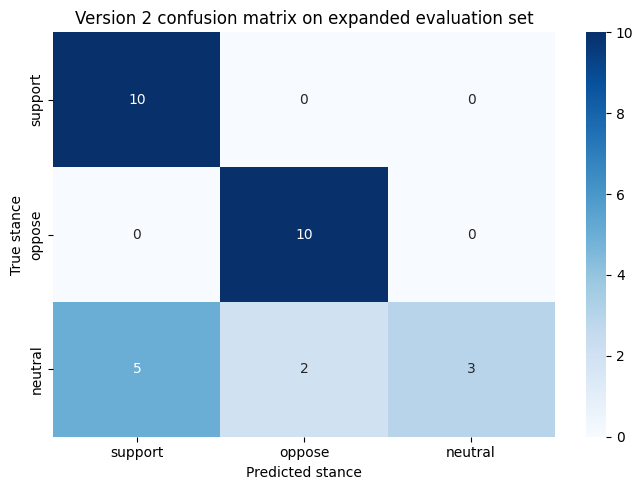

In [28]:
cm_expanded = confusion_matrix(
    expanded_evaluation_df["true_stance"],
    expanded_evaluation_df["predicted_stance_v2"],
    labels=CANDIDATE_LABELS
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_expanded,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CANDIDATE_LABELS,
    yticklabels=CANDIDATE_LABELS
)

plt.xlabel("Predicted stance")
plt.ylabel("True stance")
plt.title("Version 2 confusion matrix on expanded evaluation set")
plt.tight_layout()
plt.show()

### Interpretation

Version 2 remains the strongest prompt tested so far. The expanded evaluation set provides
a more stable indication of its behavior across different sentence types.

The remaining errors should be examined manually to determine whether they result from
ambiguous wording, limitations of zero-shot NLI, or disagreements about the stance labels.

## External benchmark: climate-change stance

To evaluate the pipeline beyond the manually constructed UBI set, we use the
`stance_climate` subset of the `tweet_eval` benchmark.

This dataset contains tweets labeled according to their stance toward the target:
**Climate change is a real concern**.

The original labels are mapped as follows:

- `none` → `neutral`
- `against` → `oppose`
- `favor` → `support`

This external dataset allows evaluation on naturally occurring social-media text rather than
only manually constructed statements.

In [29]:
!pip install -q datasets

In [31]:
from datasets import load_dataset

climate_dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "stance_climate"
)

print(climate_dataset)
print("\nLabel names:", climate_dataset["train"].features["label"].names)

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

stance_climate/train-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B / 28.1kB            

stance_climate/train-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

stance_climate/test-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 14.9kB            

stance_climate/test-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

...

stance_climate/validation-00000-of-00001(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/355 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/169 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/40 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 355
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 169
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 40
    })
})

Label names: ['none', 'against', 'favor']


In [32]:
label_names = climate_dataset["train"].features["label"].names

for i in range(5):
    example = climate_dataset["train"][i]
    print(f"Label: {label_names[example['label']]}")
    print(example["text"])
    print("-" * 80)

Label: none
Why Is The Pope Upset?  via @user #UnzippedTruth #PopeFrancis #SemST
--------------------------------------------------------------------------------
Label: favor
We support Australia's Climate Roundtable which is providing a framework for sensible debate ahead of Paris @user #SemST
--------------------------------------------------------------------------------
Label: none
It's nights like this when I'm not so fond of my long hair. I just wanna chop it all off! #heatwave #pnwgirl #SemST
--------------------------------------------------------------------------------
Label: none
#Republican party will go down in history books as party that stood in the way of #gayrights and initiative to reverse #SemST
--------------------------------------------------------------------------------
Label: favor
RT @user @user We need degrowth - stop destroying our planet, BP. #SemST
--------------------------------------------------------------------------------


In [33]:
import random

random.seed(42)

test_dataset = climate_dataset["test"]

# Official mapping for stance_climate
label_mapping = {
    0: "neutral",   # none
    1: "oppose",    # against
    2: "support"    # favor
}

# Group test indices by numeric label
indices_by_label = {0: [], 1: [], 2: []}

for index, example in enumerate(test_dataset):
    indices_by_label[example["label"]].append(index)

samples_per_class = 20
selected_indices = []

for label_id, indices in indices_by_label.items():
    selected_indices.extend(
        random.sample(indices, min(samples_per_class, len(indices)))
    )

random.shuffle(selected_indices)

climate_evaluation_df = pd.DataFrame([
    {
        "sentence": test_dataset[index]["text"],
        "true_stance": label_mapping[test_dataset[index]["label"]]
    }
    for index in selected_indices
])

climate_evaluation_df

,sentence,true_stance
0,Follow @user for information on #CFCC15 - the ...,support
1,"We are not ""killing the Earth"". The Earth has ...",oppose
2,Counting down the days until my PhD starts #77...,neutral
3,@user Jonathan Tillson from @user highlights h...,neutral
4,"What has been will be again, what has been don...",neutral
5,5 meta-analyses show 1/2 of species have chang...,support
6,"...a longer memory, and a sterner sense of jus...",neutral
7,@user @user @user @user What values is heUsing...,neutral
8,Closed door session begins. More after they de...,neutral
9,A Very Good Discussion:Ruth Valerio @user and ...,neutral


In [34]:
climate_evaluation_df["clean_sentence"] = climate_evaluation_df["sentence"].apply(clean_text)

climate_evaluation_df = climate_evaluation_df[
    climate_evaluation_df["clean_sentence"].str.len() > 0
].reset_index(drop=True)

climate_evaluation_df[["sentence", "clean_sentence", "true_stance"]]

,sentence,clean_sentence,true_stance
0,Follow @user for information on #CFCC15 - the ...,Follow user for information on CFCC15 - the cl...,support
1,"We are not ""killing the Earth"". The Earth has ...","We are not ""killing the Earth"". The Earth has ...",oppose
2,Counting down the days until my PhD starts #77...,Counting down the days until my PhD starts 77 ...,neutral
3,@user Jonathan Tillson from @user highlights h...,user Jonathan Tillson from user highlights how...,neutral
4,"What has been will be again, what has been don...","What has been will be again, what has been don...",neutral
5,5 meta-analyses show 1/2 of species have chang...,5 meta-analyses show 1 2 of species have chang...,support
6,"...a longer memory, and a sterner sense of jus...","...a longer memory, and a sterner sense of jus...",neutral
7,@user @user @user @user What values is heUsing...,user user user user What values is heUsing ref...,neutral
8,Closed door session begins. More after they de...,Closed door session begins. More after they de...,neutral
9,A Very Good Discussion:Ruth Valerio @user and ...,A Very Good Discussion:Ruth Valerio user and P...,neutral


In [35]:
climate_target_premise = "Climate change is a real concern"

climate_predictions = []

for sentence in tqdm(climate_evaluation_df["clean_sentence"], desc="Classifying climate tweets"):
    result = classify_stance_v2(
        sentences=[sentence],
        target_premise=climate_target_premise,
        batch_size=1
    )[0]

    climate_predictions.append(result["stance"])

climate_evaluation_df["predicted_stance"] = climate_predictions
climate_evaluation_df

Classifying climate tweets:   0%|          | 0/51 [00:00<?, ?it/s]

,sentence,true_stance,clean_sentence,predicted_stance
0,Follow @user for information on #CFCC15 - the ...,support,Follow user for information on CFCC15 - the cl...,support
1,"We are not ""killing the Earth"". The Earth has ...",oppose,"We are not ""killing the Earth"". The Earth has ...",oppose
2,Counting down the days until my PhD starts #77...,neutral,Counting down the days until my PhD starts 77 ...,support
3,@user Jonathan Tillson from @user highlights h...,neutral,user Jonathan Tillson from user highlights how...,support
4,"What has been will be again, what has been don...",neutral,"What has been will be again, what has been don...",oppose
5,5 meta-analyses show 1/2 of species have chang...,support,5 meta-analyses show 1 2 of species have chang...,support
6,"...a longer memory, and a sterner sense of jus...",neutral,"...a longer memory, and a sterner sense of jus...",support
7,@user @user @user @user What values is heUsing...,neutral,user user user user What values is heUsing ref...,support
8,Closed door session begins. More after they de...,neutral,Closed door session begins. More after they de...,support
9,A Very Good Discussion:Ruth Valerio @user and ...,neutral,A Very Good Discussion:Ruth Valerio user and P...,support


In [36]:
print("Zero-shot stance classification: climate-change tweets")
print(classification_report(
    climate_evaluation_df["true_stance"],
    climate_evaluation_df["predicted_stance"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("Accuracy:", accuracy_score(
    climate_evaluation_df["true_stance"],
    climate_evaluation_df["predicted_stance"]
))

Zero-shot stance classification: climate-change tweets
              precision    recall  f1-score   support

     support       0.48      0.55      0.51        20
      oppose       0.43      0.91      0.59        11
     neutral       0.80      0.20      0.32        20

    accuracy                           0.49        51
   macro avg       0.57      0.55      0.47        51
weighted avg       0.60      0.49      0.45        51

Accuracy: 0.49019607843137253


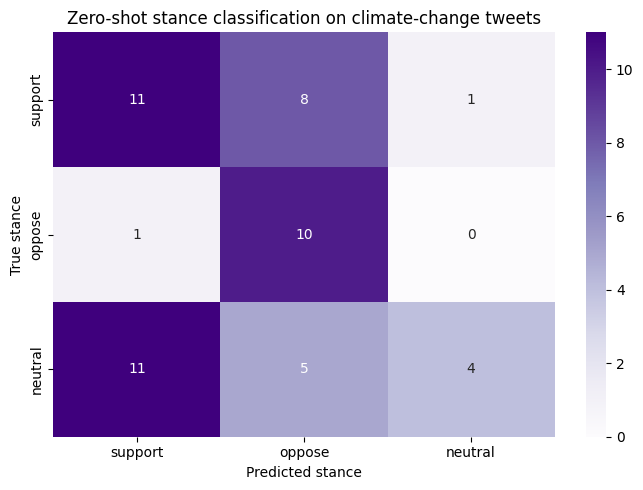

In [37]:
cm_climate = confusion_matrix(
    climate_evaluation_df["true_stance"],
    climate_evaluation_df["predicted_stance"],
    labels=CANDIDATE_LABELS
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_climate,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=CANDIDATE_LABELS,
    yticklabels=CANDIDATE_LABELS
)

plt.xlabel("Predicted stance")
plt.ylabel("True stance")
plt.title("Zero-shot stance classification on climate-change tweets")
plt.tight_layout()
plt.show()

### Error analysis

The climate-change evaluation reveals a substantial drop in performance compared with the
manually constructed UBI evaluation set.

This is expected because tweets are shorter, noisier, and often indirect. Many tweets contain
sarcasm, hashtags, mentions, or conversational context that is not sufficient to determine
stance from the tweet text alone.

The lower performance therefore reflects both the difficulty of zero-shot stance detection
and the domain shift from clean argumentative text to social-media text.

In [38]:
misclassified_df = climate_evaluation_df[
    climate_evaluation_df["true_stance"] != climate_evaluation_df["predicted_stance"]
].copy()

print(f"Number of misclassified tweets: {len(misclassified_df)}")
misclassified_df[["clean_sentence", "true_stance", "predicted_stance"]]

Number of misclassified tweets: 26


,clean_sentence,true_stance,predicted_stance
2,Counting down the days until my PhD starts 77 ...,neutral,support
3,user Jonathan Tillson from user highlights how...,neutral,support
4,"What has been will be again, what has been don...",neutral,oppose
6,"...a longer memory, and a sterner sense of jus...",neutral,support
7,user user user user What values is heUsing ref...,neutral,support
8,Closed door session begins. More after they de...,neutral,support
9,A Very Good Discussion:Ruth Valerio user and P...,neutral,support
11,user Oh for the love of Pete! I thought we wer...,neutral,oppose
12,Turn the Liverpool Plains into a coal mine...i...,support,oppose
15,Defrance: displacements due to natural disaste...,support,oppose


In [39]:
# Show a readable sample of misclassified tweets
for _, row in misclassified_df.head(10).iterrows():
    print(f"TRUE: {row['true_stance']}")
    print(f"PREDICTED: {row['predicted_stance']}")
    print(row["clean_sentence"])
    print("-" * 100)

TRUE: neutral
PREDICTED: support
Counting down the days until my PhD starts 77 tephrochronology southernhemisphere chronology oxford SemST
----------------------------------------------------------------------------------------------------
TRUE: neutral
PREDICTED: support
user Jonathan Tillson from user highlights how economic stability will be undermined by SemST
----------------------------------------------------------------------------------------------------
TRUE: neutral
PREDICTED: oppose
What has been will be again, what has been done will be done again; there is nothing new under the sun. Ecclesiastes 1:9 SemST
----------------------------------------------------------------------------------------------------
TRUE: neutral
PREDICTED: support
...a longer memory, and a sterner sense of justice than we do. -W.Berry SemST
----------------------------------------------------------------------------------------------------
TRUE: neutral
PREDICTED: support
user user user user What va

### Preprocessing consideration

The current cleaning function removes URLs and special characters. While this improves
readability for long-form text, it may remove useful stance cues in tweets, such as hashtags
and mentions.

For social-media text, a dedicated preprocessing strategy may be needed. For example, hashtags
could be preserved as lexical signals, while usernames and URLs could be replaced with
placeholder tokens.

In [40]:
def clean_tweet_text(text: str) -> str:
    """
    Tweet-specific cleaning:
    - Replace URLs and mentions with placeholders.
    - Preserve hashtag text because it may contain stance cues.
    - Normalize whitespace.
    """
    text = re.sub(r"http\S+|www\.\S+", " [URL] ", text)
    text = re.sub(r"@\w+", " [USER] ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


climate_evaluation_df["tweet_clean_sentence"] = climate_evaluation_df["sentence"].apply(clean_tweet_text)

climate_evaluation_df[["sentence", "tweet_clean_sentence", "true_stance", "predicted_stance"]]

,sentence,tweet_clean_sentence,true_stance,predicted_stance
0,Follow @user for information on #CFCC15 - the ...,Follow [USER] for information on CFCC15 - the ...,support,support
1,"We are not ""killing the Earth"". The Earth has ...","We are not ""killing the Earth"". The Earth has ...",oppose,oppose
2,Counting down the days until my PhD starts #77...,Counting down the days until my PhD starts 77 ...,neutral,support
3,@user Jonathan Tillson from @user highlights h...,[USER] Jonathan Tillson from [USER] highlights...,neutral,support
4,"What has been will be again, what has been don...","What has been will be again, what has been don...",neutral,oppose
5,5 meta-analyses show 1/2 of species have chang...,5 meta-analyses show 1/2 of species have chang...,support,support
6,"...a longer memory, and a sterner sense of jus...","...a longer memory, and a sterner sense of jus...",neutral,support
7,@user @user @user @user What values is heUsing...,[USER] [USER] [USER] [USER] What values is heU...,neutral,support
8,Closed door session begins. More after they de...,Closed door session begins. More after they de...,neutral,support
9,A Very Good Discussion:Ruth Valerio @user and ...,A Very Good Discussion:Ruth Valerio [USER] and...,neutral,support


In [41]:
tweet_predictions = []

for sentence in tqdm(climate_evaluation_df["tweet_clean_sentence"], desc="Classifying with tweet-specific cleaning"):
    result = classify_stance_v2(
        sentences=[sentence],
        target_premise=climate_target_premise,
        batch_size=1
    )[0]

    tweet_predictions.append(result["stance"])

climate_evaluation_df["predicted_stance_tweet_cleaned"] = tweet_predictions
climate_evaluation_df

Classifying with tweet-specific cleaning:   0%|          | 0/51 [00:00<?, ?it/s]

,sentence,true_stance,clean_sentence,predicted_stance,tweet_clean_sentence,predicted_stance_tweet_cleaned
0,Follow @user for information on #CFCC15 - the ...,support,Follow user for information on CFCC15 - the cl...,support,Follow [USER] for information on CFCC15 - the ...,support
1,"We are not ""killing the Earth"". The Earth has ...",oppose,"We are not ""killing the Earth"". The Earth has ...",oppose,"We are not ""killing the Earth"". The Earth has ...",oppose
2,Counting down the days until my PhD starts #77...,neutral,Counting down the days until my PhD starts 77 ...,support,Counting down the days until my PhD starts 77 ...,support
3,@user Jonathan Tillson from @user highlights h...,neutral,user Jonathan Tillson from user highlights how...,support,[USER] Jonathan Tillson from [USER] highlights...,support
4,"What has been will be again, what has been don...",neutral,"What has been will be again, what has been don...",oppose,"What has been will be again, what has been don...",oppose
5,5 meta-analyses show 1/2 of species have chang...,support,5 meta-analyses show 1 2 of species have chang...,support,5 meta-analyses show 1/2 of species have chang...,support
6,"...a longer memory, and a sterner sense of jus...",neutral,"...a longer memory, and a sterner sense of jus...",support,"...a longer memory, and a sterner sense of jus...",support
7,@user @user @user @user What values is heUsing...,neutral,user user user user What values is heUsing ref...,support,[USER] [USER] [USER] [USER] What values is heU...,support
8,Closed door session begins. More after they de...,neutral,Closed door session begins. More after they de...,support,Closed door session begins. More after they de...,support
9,A Very Good Discussion:Ruth Valerio @user and ...,neutral,A Very Good Discussion:Ruth Valerio user and P...,support,A Very Good Discussion:Ruth Valerio [USER] and...,support


In [42]:
print("Original cleaning")
print(classification_report(
    climate_evaluation_df["true_stance"],
    climate_evaluation_df["predicted_stance"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("\nTweet-specific cleaning")
print(classification_report(
    climate_evaluation_df["true_stance"],
    climate_evaluation_df["predicted_stance_tweet_cleaned"],
    labels=CANDIDATE_LABELS,
    zero_division=0
))

print("Accuracy — original cleaning:", accuracy_score(
    climate_evaluation_df["true_stance"],
    climate_evaluation_df["predicted_stance"]
))

print("Accuracy — tweet-specific cleaning:", accuracy_score(
    climate_evaluation_df["true_stance"],
    climate_evaluation_df["predicted_stance_tweet_cleaned"]
))

Original cleaning
              precision    recall  f1-score   support

     support       0.48      0.55      0.51        20
      oppose       0.43      0.91      0.59        11
     neutral       0.80      0.20      0.32        20

    accuracy                           0.49        51
   macro avg       0.57      0.55      0.47        51
weighted avg       0.60      0.49      0.45        51


Tweet-specific cleaning
              precision    recall  f1-score   support

     support       0.48      0.60      0.53        20
      oppose       0.45      0.91      0.61        11
     neutral       0.75      0.15      0.25        20

    accuracy                           0.49        51
   macro avg       0.56      0.55      0.46        51
weighted avg       0.58      0.49      0.44        51

Accuracy — original cleaning: 0.49019607843137253
Accuracy — tweet-specific cleaning: 0.49019607843137253


### Overall findings

The zero-shot stance analyzer performs reasonably well on clean, explicit argumentative
statements but struggles on noisy social-media text.

The main limitations are:
- neutral statements are often interpreted as support or opposition;
- sarcasm and indirect language are difficult to detect;
- hashtags and conversational context can carry important stance information;
- the model has not been fine-tuned on stance-specific data.

These results motivate future work using supervised fine-tuning, better tweet preprocessing,
and a more carefully filtered evaluation subset.

## Final research conclusion

This project developed a lightweight zero-shot NLP pipeline for discursive stance analysis.
The system segments argumentative text into sentence-level propositions and classifies each
proposition as supporting, opposing, or neutral toward a target premise.

The best configuration used `facebook/bart-large-mnli` with an explicit hypothesis template:

> This statement {candidate label} the following claim: [target premise].

On a manually constructed evaluation set of 30 statements about universal basic income,
the pipeline achieved 76.7% accuracy. It correctly identified all support and oppose statements,
but struggled to detect neutral statements.

On an external climate-change tweet benchmark, accuracy decreased to 49.0%. This drop reflects
domain shift, informal language, sarcasm, indirect argumentation, and the difficulty of detecting
neutral stance in short social-media posts.

The project demonstrates both the usefulness and the limitations of zero-shot NLI for
decision-support tasks. Future work should explore supervised fine-tuning, improved social-media
preprocessing, confidence calibration, and larger evaluation datasets.